# TrialPulse | Validazione dei KPI operativi

**Notebook QA e dimostrativo sui dati completamente sintetici di Novera Neuro Research.**

Il notebook usa il CSV ufficiale, la pulizia del `data_loader` e le analisi del `Data Agent` esistente. Non modifica i dati, non introduce nuove regole operative e non stabilisce quali trattamenti siano clinicamente migliori.

**Obiettivi:** controllare integrità e numerosità del dataset, osservare i KPI operativi per studio e sito, verificare i pattern attesi e produrre grafici essenziali. I risultati del notebook sono evidenze di controllo, non una nuova fonte ufficiale delle formule o delle soglie.

**Esecuzione:** aprire da Jupyter nella directory `data_agent/notebooks` (o avviare il kernel dalla root di TrialPulse) ed eseguire tutte le celle in ordine. Sono necessari gli stessi pacchetti Python usati dal progetto, oltre a `matplotlib` per i grafici. Nessun servizio HTTP, provider LLM o accesso a Internet è richiesto.


## 1. Individuazione del repository e verifica del CSV

Prima di effettuare qualsiasi elaborazione, il notebook verifica la firma SHA-256 del file ufficiale. Se il CSV non corrisponde alla versione congelata, l'esecuzione si interrompe: non sono ammessi risultati ottenuti su un dataset differente senza revisione esplicita.


In [1]:
from pathlib import Path
import hashlib
import sys

import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display

EXPECTED_SHA256 = "3f9ad9042443eeecf70071132b87032f2564a6dba4b3d81f01efb18bd8aff7ec"


def locate_repository():
    location = Path.cwd().resolve()
    for candidate in (location, *location.parents):
        if (candidate / "data/trialpulse_operations.csv").is_file() and (
            candidate / "data_agent/data_loader.py"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Repository TrialPulse non trovato. Apri il notebook dalla cartella del progetto."
    )


ROOT = locate_repository()
CSV_PATH = ROOT / "data/trialpulse_operations.csv"
current_hash = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
assert current_hash == EXPECTED_SHA256, "SHA-256 del CSV diverso dalla versione ufficiale."

sys.path.insert(0, str(ROOT / "data_agent"))
print("Repository:", ROOT.name)
print("CSV ufficiale verificato, SHA-256:", current_hash)


Repository: TrialPulse
CSV ufficiale verificato, SHA-256: 3f9ad9042443eeecf70071132b87032f2564a6dba4b3d81f01efb18bd8aff7ec


## 2. Qualità dei dati e struttura

Si utilizza `load_analytic_dataset()` per applicare le stesse operazioni della pipeline ufficiale: rimozione dei duplicati esatti, normalizzazione dello stato del partecipante, parsing delle date e segnalazione delle anomalie. Le anomalie non equivalgono automaticamente a righe escluse da ogni KPI.


In [2]:
from data_loader import load_analytic_dataset

raw = pd.read_csv(CSV_PATH, low_memory=False)
analytic, quality = load_analytic_dataset(CSV_PATH)

summary_structure = pd.DataFrame(
    [
        ("Righe fisiche", len(raw), 1508),
        ("Righe logiche", len(analytic), 1500),
        ("Colonne originali", raw.shape[1], 43),
        ("Duplicati esatti rimossi", quality["duplicates_removed"], 8),
    ],
    columns=["Controllo", "Osservato", "Atteso"],
)
summary_structure["Esito"] = summary_structure["Osservato"].eq(summary_structure["Atteso"])
display(summary_structure)
assert summary_structure["Esito"].all(), "Struttura del dataset non conforme."

quality_details = pd.DataFrame(
    [(key, str(value)) for key, value in quality.items() if key != "warnings"],
    columns=["Indicatore qualità", "Valore rilevato"],
)
display(quality_details)
print("Avvisi del loader:")
for warning in quality["warnings"]:
    print("-", warning)

# Anomalie controllate: vengono rilevate, non indiscriminatamente scartate.
assert quality["inconsistent_actual_dates"] == 15
assert quality["inconsistent_query_rows"] == 3
assert len(analytic) == 1500  # I flag di qualità non rimuovono queste righe dalla vista analitica.


,Controllo,Osservato,Atteso,Esito
0,Righe fisiche,1508,1508,True
1,Righe logiche,1500,1500,True
2,Colonne originali,43,43,True
3,Duplicati esatti rimossi,8,8,True


,Indicatore qualità,Valore rilevato
0,physical_rows,1508
1,logical_rows,1500
2,duplicates_removed,8
3,normalized_values,15
4,unparseable_dates,"{'enrollment_date': 0, 'day0_date': 0, 'target..."
5,inconsistent_actual_dates,15
6,inconsistent_query_rows,3


Avvisi del loader:
- 8 duplicati esatti rimossi dalla vista analitica.
- 15 actual_date incoerenti.
- 3 righe query incoerenti.


## 3. Riepilogo ufficiale del portfolio

Per i KPI utilizziamo `analyze_dataset()` e `AnalyzeRequest` esistenti. Il notebook si limita a trasformare in tabelle i risultati restituiti, senza duplicare il calcolo di enrollment, retention, visite o completezza.


In [3]:
from analytics import analyze_dataset
from models import AnalyzeRequest


def run_analysis(name, group_by=None, filters=None, parameters=None):
    request = AnalyzeRequest.model_validate(
        {
            "analysis": name,
            "group_by": group_by or [],
            "filters": filters or {},
            "parameters": parameters or {},
        }
    )
    return analyze_dataset(analytic, quality, request)


def analysis_table(name, group_by=None, filters=None, parameters=None):
    report = run_analysis(name, group_by, filters, parameters)
    table = pd.DataFrame(report["results"])
    return table.sort_values(group_by).reset_index(drop=True) if group_by else table


portfolio = analysis_table("portfolio_summary").iloc[0]
display(pd.DataFrame([portfolio]))
assert int(portfolio["screened_participants"]) == 194
assert int(portfolio["enrolled_participants"]) == 154
assert int(portfolio["screening_failures"]) == 40
assert int(portfolio["studies"]) == 4
assert int(portfolio["sites"]) == 8
print("Controlli sul riepilogo portfolio superati.")


,screened_participants,enrolled_participants,screening_failures,enrollment_rate,studies,sites
0,194.0,154.0,40.0,79.38,4.0,8.0


Controlli sul riepilogo portfolio superati.


### Verifica dei totali per singolo studio

Il riepilogo restituito dal Data Agent viene confrontato con le numerosità previste dal disegno sintetico congelato. È un controllo di coerenza delle fonti, non un secondo algoritmo di calcolo dell'enrollment.

In [4]:
with (ROOT / "data_agent/config/study_design.yaml").open(encoding="utf-8") as stream:
    design = yaml.safe_load(stream)

by_study = analysis_table("portfolio_summary", ["study_id"])
expected_studies = pd.DataFrame(
    [
        {"study_id": key, "screened_attesi": value["screened"], "arruolati_attesi": value["enrolled"]}
        for key, value in design["studies"].items()
    ]
)
check_studies = by_study.merge(expected_studies, on="study_id", validate="one_to_one")
check_studies["screenati_coerenti"] = check_studies["screened_participants"].eq(check_studies["screened_attesi"])
check_studies["arruolati_coerenti"] = check_studies["enrolled_participants"].eq(check_studies["arruolati_attesi"])
assert len(check_studies) == len(expected_studies) == 4
assert check_studies[["screenati_coerenti", "arruolati_coerenti"]].all().all()
display(check_studies[[
    "study_id", "screened_participants", "screened_attesi",
    "enrolled_participants", "arruolati_attesi", "screenati_coerenti", "arruolati_coerenti",
]])

,study_id,screened_participants,screened_attesi,enrolled_participants,arruolati_attesi,screenati_coerenti,arruolati_coerenti
0,NNR-DXB-03,54,54,44,44,True,True
1,NNR-ESK-02,40,40,32,32,True,True
2,NNR-PSI-01,46,46,36,36,True,True
3,NNR-SER-04,54,54,42,42,True,True


## 4. Distribuzione dei partecipanti per studio e sito

La distribuzione è descrittiva. Eventuali differenze tra studi e siti vanno interpretate insieme ai rispettivi target: un conteggio inferiore non dimostra da solo un problema di recruitment.


,study_id,screened_participants,enrolled_participants,screening_failures
0,NNR-DXB-03,54,44,10
1,NNR-ESK-02,40,32,8
2,NNR-PSI-01,46,36,10
3,NNR-SER-04,54,42,12


,site_id,enrolled_participants
0,SITE_01,22
1,SITE_02,20
2,SITE_03,11
3,SITE_04,19
4,SITE_05,21
5,SITE_06,20
6,SITE_07,22
7,SITE_08,19


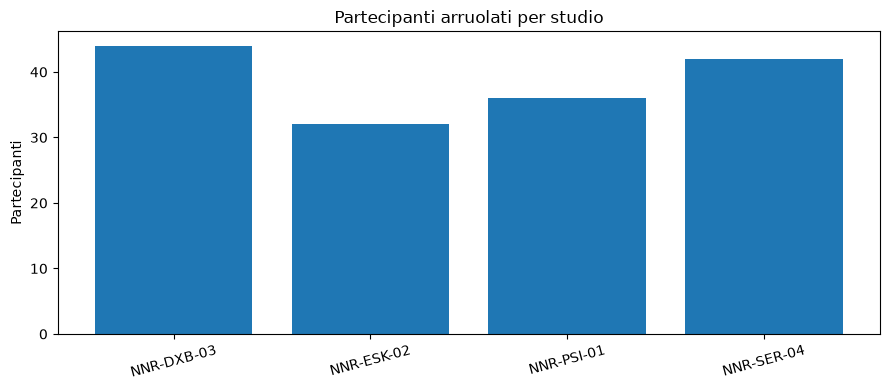

In [5]:
by_study = analysis_table("portfolio_summary", ["study_id"])
by_site = analysis_table("recruitment", ["site_id"])
display(by_study[["study_id", "screened_participants", "enrolled_participants", "screening_failures"]])
display(by_site[["site_id", "enrolled_participants"]])

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_study["study_id"], by_study["enrolled_participants"])
ax.set(title="Partecipanti arruolati per studio", ylabel="Partecipanti")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
plt.show()


## 5. Recruitment mensile rispetto ai target di progetto

Il confronto impiega i conteggi prodotti dal Data Agent e i target dichiarati in `data_agent/config/study_design.yaml`. Non applica qui la regola documentale di escalation per due mesi consecutivi sotto soglia: quella classificazione compete all'analisi parametrica ufficiale, dopo recupero della soglia dalla Knowledge Base.

Il grafico si concentra su `SITE_03`, indicato nel disegno sintetico come sito con recruitment lento. La presenza e l'intensità del pattern devono essere giudicate rispetto ai target, non in base a un semplice ordinamento dei siti.


,month,enrolled_participants,target_enrolled
0,2026-02,5,5
1,2026-03,2,5
2,2026-04,2,5
3,2026-05,1,5
4,2026-06,1,2


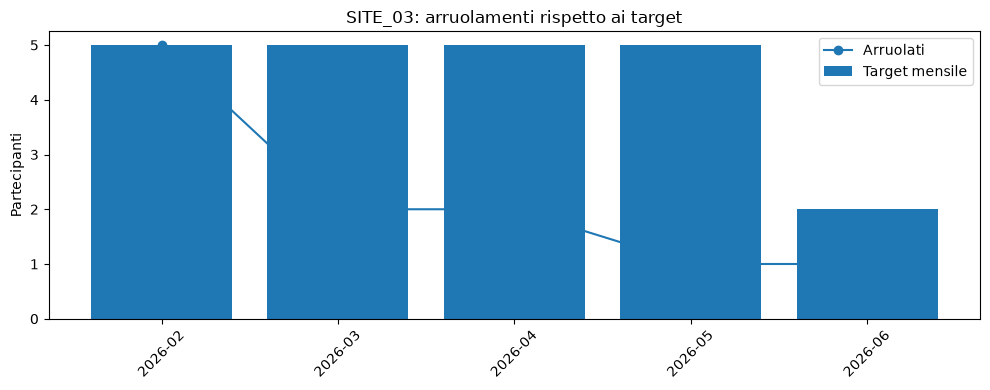

,site_id,arruolati,target,raggiungimento_percento
2,SITE_03,11,22,50.00
3,SITE_04,19,20,95.00
7,SITE_08,19,20,95.00
4,SITE_05,21,22,95.45
0,SITE_01,22,22,100.00
1,SITE_02,20,20,100.00
5,SITE_06,20,20,100.00
6,SITE_07,22,22,100.00


In [6]:
config_path = ROOT / "data_agent/config/study_design.yaml"
if not config_path.is_file():
    raise FileNotFoundError("Configurazione ufficiale mancante: data_agent/config/study_design.yaml")
monthly = analysis_table("recruitment", ["study_id", "site_id", "month"])
planned = []
for study, calendar in design["recruitment"].items():
    for site, allocation in design["site_allocation"][study].items():
        for month in calendar["months"]:
            planned.append(
                {"study_id": study, "site_id": site, "month": month,
                 "target_enrolled": allocation["monthly_target"]}
            )
planned = pd.DataFrame(planned)
comparison = planned.merge(
    monthly[["study_id", "site_id", "month", "enrolled_participants"]],
    on=["study_id", "site_id", "month"], how="left", validate="one_to_one",
)
comparison["enrolled_participants"] = comparison["enrolled_participants"].fillna(0).astype(int)

site03 = (comparison.loc[comparison["site_id"].eq("SITE_03")]
          .groupby("month", as_index=False)[["enrolled_participants", "target_enrolled"]].sum()
          .sort_values("month"))
if site03.empty:
    raise AssertionError("SITE_03 non presente nella configurazione recruitment.")
display(site03)

fig, ax = plt.subplots(figsize=(10, 4))
positions = range(len(site03))
ax.bar(positions, site03["target_enrolled"], label="Target mensile")
ax.plot(positions, site03["enrolled_participants"], marker="o", label="Arruolati")
ax.set_xticks(list(positions), site03["month"], rotation=45)
ax.set(title="SITE_03: arruolamenti rispetto ai target", ylabel="Partecipanti")
ax.legend()
fig.tight_layout()
plt.show()


# Rapporto complessivo arruolati/target, descrittivo e non una soglia di escalation.
site_recruitment = comparison.groupby("site_id", as_index=False).agg(
    arruolati=("enrolled_participants", "sum"), target=("target_enrolled", "sum")
)
site_recruitment["raggiungimento_percento"] = (
    100 * site_recruitment["arruolati"] / site_recruitment["target"]
).round(2)
display(site_recruitment.sort_values("raggiungimento_percento"))


## 6. Visite completate e visite mancate

I valori provengono da `visits`, che applica le esclusioni previste dal Data Agent (per esempio Screening e visite non attese dopo il dropout). Il pattern sintetico da verificare riguarda `SITE_07`.


,site_id,expected_visits,completed_visits,missed_visits,missed_rate
6,SITE_07,156,137,19,12.18
3,SITE_04,167,157,10,5.99
5,SITE_06,179,170,9,5.03
0,SITE_01,158,153,5,3.16
4,SITE_05,152,148,4,2.63
2,SITE_03,77,75,2,2.60
7,SITE_08,171,168,3,1.75
1,SITE_02,184,182,2,1.09


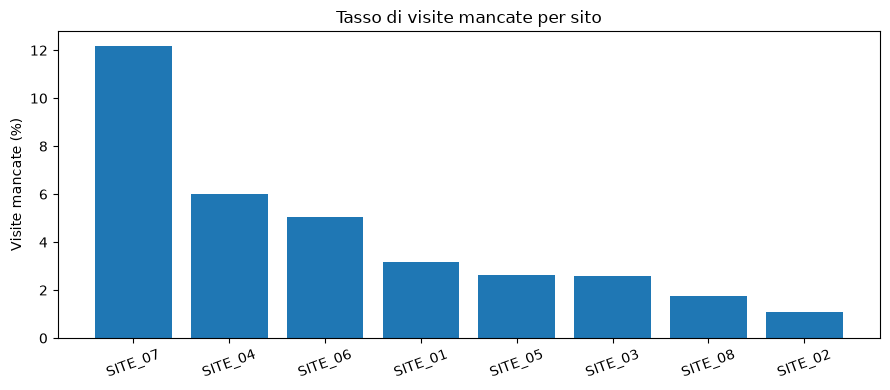

In [7]:
visits_by_site = analysis_table("visits", ["site_id"])
visits_by_site = visits_by_site.sort_values("missed_rate", ascending=False)
display(visits_by_site[
    ["site_id", "expected_visits", "completed_visits", "missed_visits", "missed_rate"]
])
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(visits_by_site["site_id"], visits_by_site["missed_rate"])
ax.set(title="Tasso di visite mancate per sito", ylabel="Visite mancate (%)")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 7. Query operative e aging

L'analisi `queries` esclude le righe query incoerenti come previsto dal codice ufficiale. Il valore massimo di aging è qui descrittivo; l'applicazione di una soglia Novera richiederebbe il relativo parametro documentale e l'analisi `query_aging_threshold`.

Il pattern sintetico di riferimento riguarda `SITE_05`.


,site_id,queries_opened_total,queries_open_total,oldest_open_query_days_max
4,SITE_05,48,23,35.0
3,SITE_04,48,11,18.0
6,SITE_07,41,10,18.0
0,SITE_01,39,15,16.0
5,SITE_06,55,13,16.0
2,SITE_03,21,5,14.0
7,SITE_08,61,10,8.0
1,SITE_02,51,8,7.0


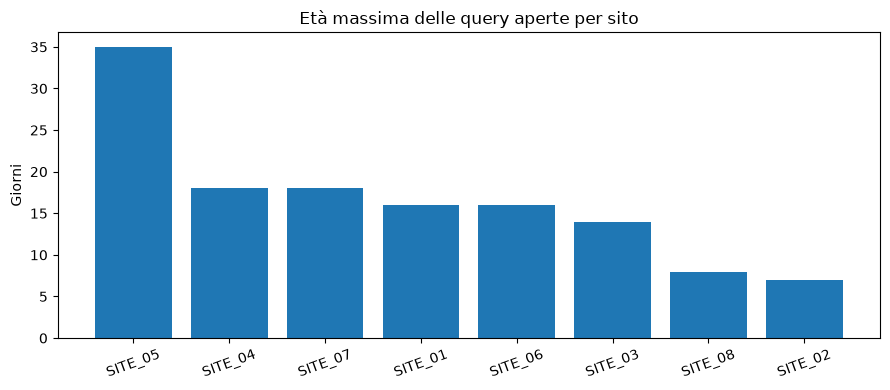

In [8]:
queries_by_site = analysis_table("queries", ["site_id"])
queries_by_site = queries_by_site.sort_values("oldest_open_query_days_max", ascending=False)
display(queries_by_site[
    ["site_id", "queries_opened_total", "queries_open_total", "oldest_open_query_days_max"]
])
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(queries_by_site["site_id"], queries_by_site["oldest_open_query_days_max"])
ax.set(title="Età massima delle query aperte per sito", ylabel="Giorni")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
plt.show()


## 8. Documentazione PSI e monitoring ESK

La funzione ufficiale `monitoring` espone sia i conteggi di documentazione sia quelli di monitoring obbligatorio. La lettura dei pattern è limitata alle combinazioni studio/sito attese nel disegno sintetico: `SITE_01` per PSI e `SITE_06` per ESK. Un'anomalia descrittiva non determina da sola la classificazione di una deviazione maggiore, che dipende dalle regole operative documentali.


In [9]:
monitoring_by_study_site = analysis_table("monitoring", ["study_id", "site_id"])
focus = monitoring_by_study_site.loc[
    (monitoring_by_study_site["study_id"].eq("NNR-PSI-01") & monitoring_by_study_site["site_id"].eq("SITE_01"))
    | (monitoring_by_study_site["study_id"].eq("NNR-ESK-02") & monitoring_by_study_site["site_id"].eq("SITE_06"))
]
columns = [
    "study_id", "site_id", "documentation_required_visits", "documentation_incomplete_visits",
    "monitoring_required_visits", "monitoring_incomplete_visits",
]
display(focus[columns])


,study_id,site_id,documentation_required_visits,documentation_incomplete_visits,monitoring_required_visits,monitoring_incomplete_visits
6,NNR-ESK-02,SITE_06,0,0,83,12
8,NNR-PSI-01,SITE_01,9,3,9,0


## 9. Completezza dei dati

Il Data Agent calcola la completezza come rapporto fra le somme delle valutazioni completate e di quelle richieste. Qui mostriamo i risultati descrittivi senza riclassificarli tramite soglie. La classificazione attenzione/escalation si ottiene con `completeness_threshold` e parametri recuperati dalla documentazione operativa.


In [10]:
completeness_by_site = analysis_table("completeness", ["site_id"])
display(completeness_by_site[
    ["site_id", "required_assessments_total", "missing_assessments_total", "completeness_rate"]
])


,site_id,required_assessments_total,missing_assessments_total,completeness_rate
0,SITE_01,807,26,96.78
1,SITE_02,1048,24,97.71
2,SITE_03,423,12,97.16
3,SITE_04,911,25,97.26
4,SITE_05,800,17,97.88
5,SITE_06,974,30,96.92
6,SITE_07,742,17,97.71
7,SITE_08,963,16,98.34


## 10. Ground truth: verifica osservabile dei pattern sintetici

Le aspettative sul comportamento dei siti sono definite nel disegno sintetico approvato. La tabella seguente **le mette alla prova usando esclusivamente i KPI già restituiti dal Data Agent** e i target in configurazione.

Sono verificati cinque pattern specifici: recruitment, aging delle query, visite mancate, documentazione PSI e monitoring ESK. Per `SITE_02` e `SITE_08` presentiamo indicatori descrittivi di confronto, senza inventare un punteggio aggregato o dichiarare che siano superiori per ogni singolo KPI.

Le verifiche qui presenti non sostituiscono il recupero delle regole Novera dalla Knowledge Base e non assegnano escalation.

In [11]:
recruitment_rank = site_recruitment.set_index("site_id")["raggiungimento_percento"]
missed_rank = visits_by_site.set_index("site_id")["missed_rate"]
query_age_rank = queries_by_site.set_index("site_id")["oldest_open_query_days_max"]
monitoring_rank = monitoring_by_study_site.set_index(["study_id", "site_id"])

psi_docs = monitoring_rank.loc[("NNR-PSI-01", "SITE_01"), "documentation_incomplete_visits"]
esk_monitor = monitoring_rank.loc[("NNR-ESK-02", "SITE_06"), "monitoring_incomplete_visits"]

pattern_checks = pd.DataFrame([
    {"Pattern": "SITE_03 recruitment lento",
     "Evidenza": f"{recruitment_rank['SITE_03']:.2f}% del target cumulato",
     "Verifica": recruitment_rank.idxmin() == "SITE_03"},
    {"Pattern": "SITE_05 query aging elevato",
     "Evidenza": f"{query_age_rank['SITE_05']:.0f} giorni di aging massimo",
     "Verifica": query_age_rank.idxmax() == "SITE_05"},
    {"Pattern": "SITE_07 visite mancate elevate",
     "Evidenza": f"{missed_rank['SITE_07']:.2f}% di visite mancate",
     "Verifica": missed_rank.idxmax() == "SITE_07"},
    {"Pattern": "SITE_01 / PSI documentazione incompleta",
     "Evidenza": f"{psi_docs:.0f} visite PSI con documentazione incompleta",
     "Verifica": psi_docs > 0 and psi_docs == monitoring_rank.loc["NNR-PSI-01", "documentation_incomplete_visits"].max()},
    {"Pattern": "SITE_06 / ESK monitoring incompleto",
     "Evidenza": f"{esk_monitor:.0f} visite ESK con monitoring incompleto",
     "Verifica": esk_monitor > 0 and esk_monitor == monitoring_rank.loc["NNR-ESK-02", "monitoring_incomplete_visits"].max()},
])
display(pattern_checks)
assert pattern_checks["Verifica"].all(), "Almeno un pattern sintetico non corrisponde ai dati ufficiali."

# Nessuna classifica composita: un piccolo confronto descrittivo di alcuni KPI.
good_sites = ["SITE_02", "SITE_08"]
good_performers = (
    visits_by_site[["site_id", "missed_rate", "completion_rate"]]
    .merge(queries_by_site[["site_id", "oldest_open_query_days_max", "open_rate"]],
           on="site_id", validate="one_to_one")
    .merge(completeness_by_site[["site_id", "completeness_rate"]],
           on="site_id", validate="one_to_one")
)
display(good_performers.loc[good_performers["site_id"].isin(good_sites)].sort_values("site_id"))
print("Cinque pattern verificati sui dati sintetici; SITE_02/SITE_08 mostrati senza score composito.")

,Pattern,Evidenza,Verifica
0,SITE_03 recruitment lento,50.00% del target cumulato,True
1,SITE_05 query aging elevato,35 giorni di aging massimo,True
2,SITE_07 visite mancate elevate,12.18% di visite mancate,True
3,SITE_01 / PSI documentazione incompleta,3 visite PSI con documentazione incompleta,True
4,SITE_06 / ESK monitoring incompleto,12 visite ESK con monitoring incompleto,True


,site_id,missed_rate,completion_rate,oldest_open_query_days_max,open_rate,completeness_rate
7,SITE_02,1.09,98.91,7.0,15.69,97.71
6,SITE_08,1.75,98.25,8.0,16.39,98.34


Cinque pattern verificati sui dati sintetici; SITE_02/SITE_08 mostrati senza score composito.


## 11. Conclusioni e limiti

- Il controllo dell'hash, della struttura e delle numerosità fornisce una verifica riproducibile dell'integrità del dataset.
- I KPI presentati provengono dalle funzioni del Data Agent: non sono ricavati da formule alternative definite in questo notebook.
- I grafici permettono di esaminare pattern operativi sintetici, ma non dimostrano automaticamente la conformità a soglie o procedure.
- Per out-of-window servono le finestre visita recuperate dalla Knowledge Base. Non vengono inventate o codificate nel notebook.
- Per escalation su query, recruitment, completezza e deviazioni servono i parametri documentali e l'analisi pertinente del Data Agent.
- Le variabili di efficacia e safety sono sintetiche e non consentono raccomandazioni terapeutiche né graduatorie cliniche fra trattamenti.

**Checklist di esecuzione:** tutte le celle completate senza errori, SHA-256 confermato, controlli di struttura e portfolio superati, grafici visibili, osservazioni sui pattern documentate separatamente.
